# Used Car Price Data Preparation and Feature Engineering

**Preparing 426,880 Craigslist used-car listings for price modeling: cleaning, outlier treatment, train and test split, scaling and encoding**

**Date:** November 4, 2026

## 1. Business context

Online marketplaces for used vehicles host hundreds of thousands of listings in which price, mileage and vehicle attributes are typed in by the sellers themselves. Without a reference price, buyers cannot tell whether an ad is fairly priced, and the platform cannot flag listings that are overpriced, underpriced or mistyped. A price-estimation model could provide that reference, but only if it is trained on data that has been cleaned and transformed consistently. The listings contain missing answers, placeholder prices and impossible values, so the data must be prepared before any model is trained.

## 2. Project objective

This project prepares raw used-car listings for price modeling to:
- select the variables relevant to price estimation and document them in a data dictionary;
- handle missing values and invalid records with explicit, justified rules;
- split the data into training and test sets before any step that learns from the data, to avoid data leakage;
- detect and treat outliers in price, mileage and vehicle age with limits calculated on the training set only and applied to both sets;
- reduce the skewness of the numeric variables, bring them to a comparable scale and encode the categorical variables according to their cardinality; and
- produce a training set and a test set that are ready for model training.

The project is data preparation. It does not train a model or estimate its performance.

## 3. Scope and limitations

- The prices are asking prices posted by sellers, not final sale prices, and the listings cover about one month in spring 2021, so the data describes that market snapshot only.
- All fields are typed by sellers and contain errors, which is why validity rules are applied before outlier detection.
- The validity rules remove only values that cannot be real, and the outliers are identified with an interquartile range (IQR) rule calculated on the training set, so no price, mileage or age limit is chosen by hand. The IQR rule still removes some legitimate high-end and classic vehicles, so the result is best suited to the mainstream used-car market.
- Removing the rows with missing values in nearly complete columns reduces the sample.
- The raw file is not included in the repository because of its size.

## 4. Dataset source

The file used for this project is `vehicles.csv`, from the *Used Cars Dataset* published on Kaggle by Austin Reese (Craigslist cars and trucks listings in the United States): https://www.kaggle.com/datasets/austinreese/craigslist-carstrucks-data. The file must be downloaded from Kaggle and saved in the `data` folder before running the notebook.

## 5. Load the data

The CSV file is located in the `data` folder of this project, which makes the analysis easier to reproduce on another computer. The libraries are imported once, in the same cell as the data. The random seed and the share of data reserved for testing are defined here, so the whole notebook is reproducible and easy to adjust. The number of raw rows is stored to report how many rows each cleaning step removes.

In [1]:
# Import the libraries used to load, clean, transform, and visualize the data.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PowerTransformer, MinMaxScaler, OneHotEncoder
from category_encoders.binary import BinaryEncoder

# Define the random seed and the share of data reserved for testing.
RANDOM_STATE = 42
TEST_SIZE = 0.2

# Load the CSV file into a pandas DataFrame for analysis.
df = pd.read_csv("../data/vehicles.csv")

# Store the number of raw rows to report the cost of each cleaning step later.
raw_rows = len(df)

print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}")

Rows: 426880 | Columns: 26


In [2]:
# Define a function that summarizes how many rows a cleaning step removed.
def removal_summary(rows_before, rows_after, label):
    """Summarize the rows before and after a cleaning step in a one-row table."""
    rows_removed = rows_before - rows_after
    percentage_removed = round(rows_removed / rows_before * 100, 2)

    return pd.DataFrame({
        "Rows before": [rows_before],
        "Rows after": [rows_after],
        "Rows removed": [rows_removed],
        "Removed (%)": [percentage_removed]
    }, index=[label])

### Data dictionary

The raw file has 26 columns. Eleven variables reach the final dataset: the target, `price`, and ten predictors, one of which (`age`) is derived from the model year. The other columns are removed for the reasons listed in the second table.

#### Variables used (11 columns)

| Variable | Description | Type | Role |
|---|---|---|---|
| `price` | Asking price of the vehicle, in US dollars | Numeric | Target |
| `age` | Age of the vehicle in years at the time of the listing, derived from the model year (`year`) in section 9 | Numeric | Predictor |
| `odometer` | Miles driven, as reported by the seller | Numeric | Predictor |
| `manufacturer` | Vehicle brand | Categorical, low cardinality | Predictor |
| `fuel` | Fuel type | Categorical, low cardinality | Predictor |
| `title_status` | Legal status of the title (clean, rebuilt, salvage, etc.) | Categorical, low cardinality | Predictor |
| `transmission` | Transmission type | Categorical, low cardinality | Predictor |
| `type` | Body type (sedan, SUV, pickup, etc.) | Categorical, low cardinality | Predictor |
| `state` | US state where the ad was posted | Categorical, low cardinality | Predictor |
| `region` | Craigslist region where the ad was posted | Categorical, high cardinality | Predictor |
| `model` | Vehicle model name, typed by the seller | Categorical, high cardinality | Predictor |

#### Columns removed (16 columns)

| Column | Description | Reason for removal | Section |
|---|---|---|---|
| `id` | Listing identifier | Identifier | 7 |
| `url` | Link to the listing | Identifier | 7 |
| `image_url` | Link to the listing image | Identifier | 7 |
| `description` | Free-text description of the ad | Free text | 7 |
| `VIN` | Vehicle identification number | Identifier | 7 |
| `region_url` | Link to the region page | Repeats `region` | 7 |
| `lat` | Latitude of the posting | Summarized by `state` and `region` | 7 |
| `long` | Longitude of the posting | Summarized by `state` and `region` | 7 |
| `condition` | Condition reported by the seller | 40.79% missing values | 8 |
| `cylinders` | Number of cylinders | 41.62% missing values | 8 |
| `drive` | Drive type | 30.59% missing values | 8 |
| `size` | Vehicle size class | 71.77% missing values | 8 |
| `paint_color` | Paint color | 30.50% missing values | 8 |
| `county` | County of the posting | Empty column (100% missing values) | 8 |
| `year` | Model year | Replaced by `age` | 9 |
| `posting_date` | Date and time the ad was posted | Used only to define the reference year for `age` | 9 |

## 6. Inspect the dataset structure

Before any column is removed, the structure of the raw file is reviewed. The data types and non-null counts show where the missing values are, and the range of posting dates shows which period the listings cover. The posting dates are still stored as text at this stage.

In [3]:
# Review data types and non-null counts before choosing any transformations.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 26 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   id            426880 non-null  int64  
 1   url           426880 non-null  str    
 2   region        426880 non-null  str    
 3   region_url    426880 non-null  str    
 4   price         426880 non-null  int64  
 5   year          425675 non-null  float64
 6   manufacturer  409234 non-null  str    
 7   model         421603 non-null  str    
 8   condition     252776 non-null  str    
 9   cylinders     249202 non-null  str    
 10  fuel          423867 non-null  str    
 11  odometer      422480 non-null  float64
 12  title_status  418638 non-null  str    
 13  transmission  424324 non-null  str    
 14  VIN           265838 non-null  str    
 15  drive         296313 non-null  str    
 16  size          120519 non-null  str    
 17  type          334022 non-null  str    
 18  paint_color   2

In [4]:
# Convert the posting dates to datetime in UTC, because the text values mix different time zone offsets.
posting_dates = pd.to_datetime(df["posting_date"], utc=True)

# Calculate the period covered by the listings.
first_posting = posting_dates.min()
last_posting = posting_dates.max()
days_covered = (last_posting - first_posting).days
missing_dates = posting_dates.isna().sum()

# Summarize the period in one table.
pd.DataFrame(
    {"Value": [first_posting, last_posting, days_covered, missing_dates]},
    index=["First posting (UTC)", "Last posting (UTC)", "Days covered", "Missing dates"]
)

,Value
First posting (UTC),2021-04-04 07:00:25+00:00
Last posting (UTC),2021-05-05 04:24:09+00:00
Days covered,30
Missing dates,68


### Initial structure findings

The file contains 426,880 listings and 26 columns. `price`, `region` and `state` are complete, and `county` is entirely empty. Among the other incomplete columns, `size` has values for only 120,519 listings, `condition` for 252,776 and `cylinders` for 249,202. The columns `id`, `url`, `image_url`, `description` and `VIN` identify or describe a single listing and carry no information about price by themselves. The posting dates range from April 4 to May 5, 2021 (UTC), a span of 30 days, so the data covers about one month and is a snapshot of one market period.

## 7. Select the columns

Columns that carry no predictive information are removed right away: identifiers and free text (`id`, `url`, `image_url`, `description` and `VIN`) and redundant location fields (`region_url` repeats `region`, and `lat` and `long` are already summarized by `state` and `region`).

`posting_date` is kept for now. It is needed to define the reference year for the vehicle age in section 9, and it is dropped once that is done.

In [5]:
# Drop identifiers, free text and redundant location columns
columns_to_drop = ['id', 'url', 'image_url', 'description', 'VIN', 'region_url', 'lat', 'long']
df.drop(columns_to_drop, axis=1, inplace=True)

In [6]:
# Confirm the remaining columns and their non-null counts.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 426880 entries, 0 to 426879
Data columns (total 18 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   region        426880 non-null  str    
 1   price         426880 non-null  int64  
 2   year          425675 non-null  float64
 3   manufacturer  409234 non-null  str    
 4   model         421603 non-null  str    
 5   condition     252776 non-null  str    
 6   cylinders     249202 non-null  str    
 7   fuel          423867 non-null  str    
 8   odometer      422480 non-null  float64
 9   title_status  418638 non-null  str    
 10  transmission  424324 non-null  str    
 11  drive         296313 non-null  str    
 12  size          120519 non-null  str    
 13  type          334022 non-null  str    
 14  paint_color   296677 non-null  str    
 15  county        0 non-null       float64
 16  state         426880 non-null  str    
 17  posting_date  426812 non-null  str    
dtypes: float64(3), 

### Column selection findings

Eight columns were removed, which leaves 18 columns. The number of rows does not change in this step.

## 8. Assess missing values

Missing values are handled with three rules, applied in this order:

1. Columns with 30% or more missing values are dropped. Imputing that much information would mostly invent data rather than recover it. `drive` (30.59%) and `paint_color` (30.50%) are only just above the threshold, so the rule is a judgment call for those two columns. It also assumes that the missingness is not tied to the price, which is not tested here.
2. Rows with a missing value in columns that are almost complete (less than 5% missing) are dropped, since the loss is small and no values have to be estimated.
3. A column that is still incomplete after the first two rules is filled with an explicit `unknown` category instead of its most frequent value. Using the mode would assign the most common category to a large share of listings and distort that variable's distribution, while `unknown` keeps the fact that the seller did not report it.

The percentage of rows removed is reported so the cost of the cleaning is visible.

In [7]:
# Calculate the percentage of missing values per column
missing_values = df.isnull().sum()
missing_percentage = (missing_values / len(df) * 100).round(2)

# Combine the counts and percentages in one table.
missing_summary = pd.DataFrame({
    "Variable": missing_values.index,
    "Missing Values": missing_values.values,
    "Missing Percentage": missing_percentage.values
})

missing_summary = missing_summary.sort_values("Missing Percentage", ascending=False)

missing_summary

,Variable,Missing Values,Missing Percentage
15,county,426880,100.00
12,size,306361,71.77
6,cylinders,177678,41.62
5,condition,174104,40.79
11,drive,130567,30.59
14,paint_color,130203,30.50
13,type,92858,21.75
3,manufacturer,17646,4.13
9,title_status,8242,1.93
4,model,5277,1.24


In [8]:
# Drop columns with 30% or more missing values
columns_30_missing = missing_percentage[missing_percentage >= 30].index.tolist()
print("Columns dropped:", columns_30_missing)
df.drop(columns=columns_30_missing, inplace=True)

Columns dropped: ['condition', 'cylinders', 'drive', 'size', 'paint_color', 'county']


In [9]:
# Drop rows with missing values in columns with less than 5% missing
columns_5_missing = missing_percentage[missing_percentage < 5].index.tolist()
print("Columns with 5% or less missing records:", columns_5_missing)
df.dropna(subset=columns_5_missing, inplace=True)

Columns with 5% or less missing records: ['region', 'price', 'year', 'manufacturer', 'model', 'fuel', 'odometer', 'title_status', 'transmission', 'state', 'posting_date']


In [10]:
# Report how many rows the missing-value rules removed.
rows_after_missing = len(df)
removal_summary(raw_rows, rows_after_missing, "Missing-value rules")

,Rows before,Rows after,Rows removed,Removed (%)
Missing-value rules,426880,389604,37276,8.73


In [11]:
# Count the number of missing values per column
df.isna().sum()

region              0
price               0
year                0
manufacturer        0
model               0
fuel                0
odometer            0
title_status        0
transmission        0
type            82628
state               0
posting_date        0
dtype: int64

In [12]:
# Fill the remaining missing values with an 'unknown' category
df["type"] = df["type"].fillna("unknown")

In [13]:
# Verify that all missing values have been handled
df.isna().sum()

region          0
price           0
year            0
manufacturer    0
model           0
fuel            0
odometer        0
title_status    0
transmission    0
type            0
state           0
posting_date    0
dtype: int64

### Missing value findings

Six columns reached the 30% threshold and were dropped: `county` (100% missing), `size` (71.77%), `cylinders` (41.62%), `condition` (40.79%), `drive` (30.59%) and `paint_color` (30.50%). Eleven of the remaining columns have less than 5% missing values, the highest being `manufacturer` (4.13%). The rows with a missing value in any of them were removed, which reduced the dataset from 426,880 to 389,604 listings (37,276 rows, 8.7%).

`type` is missing in 21.75% of the raw listings (82,628 rows after the removal), which is too many to drop. Those listings were assigned the category `unknown`, which keeps the information that the seller did not report the body type.

## 9. Create the vehicle age and apply validity rules

The model year is converted into vehicle age, which is easier to interpret and relates more directly to price. Age is calculated against a fixed reference year taken from the posting dates, not from the current date of the machine, so the result does not change every time the notebook is run. Once `age` exists, `year` and `posting_date` are dropped.

User-entered listings contain values that cannot be real or that are default entries, such as prices of zero. These are errors rather than outliers, so they are removed with validity rules before any statistical outlier detection. The rules in this section only remove such values, and each one is tied to the evidence reviewed here. They do not set any price, mileage or age limit by hand: whether an unusually high or low value is an outlier is decided in section 11, with a statistical rule calculated on the training set. The validity rules use only the values of each row, not statistics learned from the data, so they can be applied before the split without leaking information from the test set.

In [14]:
# Define the reference year from the posting dates
df["posting_date"] = pd.to_datetime(df["posting_date"], utc=True)
reference_year = df["posting_date"].dt.year.max()

In [15]:
# Create the age column and drop year and posting_date
df["age"] = reference_year - df["year"]
df.drop(columns=["year", "posting_date"], inplace=True)

In [16]:
# Summarize the numeric variables with extreme percentiles.
variables = ["price", "age", "odometer"]
percentiles = [0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]

df[variables].describe(percentiles=percentiles).map("{:,.1f}".format)

,price,age,odometer
count,"389,604.0","389,604.0","389,604.0"
mean,"63,955.3",9.4,"96,352.4"
std,"11,448,646.0",8.6,"191,418.1"
min,0.0,-1.0,0.0
1%,0.0,1.0,15.0
5%,0.0,1.0,"7,500.0"
25%,"5,995.0",4.0,"38,093.0"
50%,"13,995.0",7.0,"85,753.0"
75%,"26,590.0",12.0,"133,315.0"
95%,"43,987.8",22.0,"201,928.5"


In [17]:
# Count the listings that would break each validity rule.
price_zero = (df["price"] == 0).sum()
odometer_low = (df["odometer"] <= 2).sum()
age_impossible = (df["age"] < -1).sum()

# Summarize the counts and the share of rows they represent.
validity_summary = pd.DataFrame(
    {"Rows": [price_zero, odometer_low, age_impossible]},
    index=["price == 0", "odometer <= 2", "age < -1"]
)
validity_summary["Share of rows (%)"] = (validity_summary["Rows"] / len(df) * 100).round(2)

validity_summary

,Rows,Share of rows (%)
price == 0,28576,7.33
odometer <= 2,2951,0.76
age < -1,0,0.00


In [18]:
# Review the age of the vehicles that report 2 miles or fewer, to check whether they can be new vehicles.
df.loc[df["odometer"] <= 2, "age"].describe()

count    2951.000000
mean       16.375466
std        18.389219
min        -1.000000
25%         6.000000
50%        11.000000
75%        16.000000
max        98.000000
Name: age, dtype: float64

In [19]:
# Count the listings for each of the smallest odometer readings.
df.loc[df["odometer"] <= 10, "odometer"].value_counts().sort_index()

odometer
0.0     1301
1.0     1583
2.0       67
3.0       48
4.0      133
5.0      137
6.0       28
7.0       25
8.0       23
9.0       30
10.0     331
Name: count, dtype: int64

### Evidence for the validity rules

Each rule removes values that cannot be real or that are default entries, and the evidence below refers to the group the rule removes.

**Price greater than 0.** 28,576 listings (7.33% of the rows) have a price of \$0. A price of zero is a missing price and not an asking price, and it cannot be handled on the logarithmic scale used in section 11. Other implausible prices, such as \$1 or values in the billions, are not removed here. They are identified by the statistical limits of section 11, so that no price cutoff has to be chosen by hand.

**Odometer greater than 2 miles.** 2,951 listings report 2 miles or fewer, and 1,301 of them report exactly 0. If these were new vehicles, their age would be close to 0, but the median age is 11 years and the 25th percentile is 6 years, so at least three quarters of them are more than 6 years old. These readings are therefore default values and not real mileage. The cutoff of 2 miles is the group whose age was reviewed above. Readings above 2 miles may also contain defaults, but the evidence does not separate them from low-mileage vehicles, so they are kept.

**Age greater than or equal to -1.** Age is the reference year minus the model year, so a vehicle of the next model year has an age of -1. A vehicle cannot be more than one model year ahead of its listing, so an age below -1 is impossible. No listing breaks this rule in this dataset, and the rule is kept as a safeguard.

| Variable | Rule | Reason |
|---|---|---|
| `price` | Greater than 0 | A price of zero is a missing price |
| `odometer` | Greater than 2 miles | Readings of 0 to 2 miles on vehicles that are years old are default values |
| `age` | At least -1 | A vehicle cannot be more than one model year ahead of its listing |

In [20]:
# Remove the records that break the validity rules.
valid = (
    (df["price"] > 0)       # a price of zero is a missing price
    & (df["odometer"] > 2)  # readings of 0 to 2 miles on old vehicles are default values
    & (df["age"] >= -1)     # a vehicle cannot be more than one model year ahead of its listing
)
df_clean = df[valid].copy()

# Report how many rows the validity rules removed.
rows_after_validity = len(df_clean)
removal_summary(rows_after_missing, rows_after_validity, "Validity rules")

,Rows before,Rows after,Rows removed,Removed (%)
Validity rules,389604,358890,30714,7.88


### Validity rule findings

The table above reports how many listings the validity rules removed. The rules only remove prices and mileages that cannot be real, so listings with unusual but possible values remain in the dataset. Those values, which include the placeholder prices and the extreme mileages and ages, are handled by the statistical limits of section 11.

## 10. Split into training and test sets

The data is divided into a training set and a test set before any step that learns from the data. The outlier limits of section 11, the transformations and scalers of section 12 and the encoders of section 13 are fitted on the training set only and then applied to the test set. If they were fitted on all the data, information from the test set would leak into the training process and the evaluation of any future model would be too optimistic.

The split is done on the cleaned dataset, which still contains the target `price`, because the outlier limits of section 11 include the price. The target is separated from the predictors after the outliers are removed.

The same logic applies to duplicated listings. Craigslist ads are often reposted, so exact duplicates are counted before the split. They are reported but not removed in this project, and the final section lists this as a limitation.

In [21]:
# Count exact duplicated listings, which could end up in both the training and the test set.
duplicated_rows = df_clean.duplicated().sum()
duplicated_percentage = round(duplicated_rows / len(df_clean) * 100, 2)

pd.DataFrame(
    {"Duplicated listings": [duplicated_rows], "Share of listings (%)": [duplicated_percentage]},
    index=["Cleaned dataset"]
)

,Duplicated listings,Share of listings (%)
Cleaned dataset,44773,12.48


In [22]:
# Split the cleaned dataset into training and test sets.
train_df, test_df = train_test_split(
    df_clean,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

# Report the size of each set.
pd.DataFrame(
    {"Rows": [len(train_df), len(test_df)]},
    index=["Training set", "Test set"]
)

,Rows
Training set,287112
Test set,71778


### Split findings

The cleaned dataset was divided into a training set and a test set (80% and 20%), and the table above reports the number of rows in each. Both sets still contain the target `price`, which is separated from the predictors in section 11 after the outliers are removed.

## 11. Detect and remove outliers

An outlier is a value that is very different from the rest of the data. Some outliers are errors and some are real but unusual. This section explains why they are removed, how they are identified and what the removal costs.

### Why the outliers are removed

- **Some extreme values are errors that cannot be corrected.** In the raw data, the highest prices include keyboard sequences (`1234567890` and `123456789`) and the same \$3,736,928,711 for two different vehicles (a Tundra and a 4Runner), and the highest odometer reading is 10,000,000 miles. The true value is unknown, so these listings cannot be repaired.
- **Extreme values distort the next steps.** Min-Max scaling (section 12) uses the minimum and the maximum of each variable. With a maximum of 10,000,000 miles, a vehicle with about 268,000 miles, the 99th percentile of the odometer in the raw data, would be placed at about 0.03 on a scale from 0 to 1, and almost all realistic mileages would be squeezed together near 0. Yeo-Johnson also uses all the values to fit its parameter, so extreme values pull it as well.
- **Some extreme values are real but belong to another market.** In the raw data, 3,775 listings are older than 50 years, and a sample of them showed classic cars (a Chevrolet C10, a Ford Model T). Their prices depend on collector value and not on age and mileage as in a regular used car. This project prepares data to estimate the price of mainstream used cars.
- **Removing is preferred to correcting.** The true value of an error is unknown, and replacing an extreme value with the limit would create a price or a mileage that nobody listed. The listings are removed instead.

The cost is that some real listings are removed too, such as luxury cars, classic cars and vehicles with very high mileage. The removal table below measures how many listings are lost.

### How the outliers are identified

The interquartile range (IQR) rule is used: the first quartile (Q1) and the third quartile (Q3) are calculated, the IQR is Q3 minus Q1, and a value is an outlier if it is below Q1 minus 1.5 times the IQR or above Q3 plus 1.5 times the IQR. The multiplier of 1.5 is the conventional value of the rule. The same rule is applied to `price`, `age` and `odometer`, so no limit is chosen by hand.

The limits are calculated on the training set only and then applied to both sets. The test set represents data that has not been seen yet, so it must not influence any limit. A listing is removed if it is outside the limits of any of the three variables.

### Why price uses a logarithmic scale

The logarithm in base 10 (`log10`) of a price tells how many times the price has been multiplied by 10: \$10 has a log10 of 1, \$100 a log10 of 2, \$1,000 a log10 of 3, \$10,000 a log10 of 4 and \$100,000 a log10 of 5. Equal steps on this scale are equal ratios: a car that is ten times more expensive is always one unit higher, whether it goes from \$1,000 to \$10,000 or from \$10,000 to \$100,000.

The prices in this dataset go from a few dollars to billions of dollars, and most real cars cost between a few thousand and a few tens of thousands. On the dollar scale, the few extremely high prices stretch the upper end of the distribution and inflate the IQR. As a result, the lower limit falls below zero, so no low price such as \$1 can be flagged, while the upper limit still cuts many ordinary expensive cars. On the log scale the distribution is much more symmetric, so one rule can flag prices that are too low and prices that are too high. The comparison table below shows both scales.

The logarithm is used only to calculate the limits. The two limits are converted back to dollars (10 raised to the limit), and the price stays in dollars in the dataset.

In [23]:
# Define the function that calculates the limits used to identify outliers.
def outlier_limits(column):
    """Calculate the lower and upper limits of the IQR rule for a numeric column."""
    Q1 = column.quantile(0.25)
    Q3 = column.quantile(0.75)
    IQR = Q3 - Q1
    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR
    return lower_limit, upper_limit

In [24]:
# Calculate the price limits on the dollar scale, using the training set only.
lower_price_raw, upper_price_raw = outlier_limits(train_df["price"])

# Calculate the price limits on the log10 scale and convert them back to dollars.
log_price_train = np.log10(train_df["price"])
lower_log_price, upper_log_price = outlier_limits(log_price_train)
lower_price = 10 ** lower_log_price
upper_price = 10 ** upper_log_price

# Compare the two scales, including the share of training listings flagged as outliers.
share_raw = (1 - train_df["price"].between(lower_price_raw, upper_price_raw).mean()) * 100
share_log = (1 - train_df["price"].between(lower_price, upper_price).mean()) * 100

pd.DataFrame({
    "Lower limit ($)": [lower_price_raw, lower_price],
    "Upper limit ($)": [upper_price_raw, upper_price],
    "Outliers in training set (%)": [share_raw, share_log]
}, index=["Dollar scale", "Log10 scale"]).round(2)

,Lower limit ($),Upper limit ($),Outliers in training set (%)
Dollar scale,-23112.50,58507.50,1.74
Log10 scale,1043.57,200379.39,3.27


In [25]:
# Calculate the limits of age and odometer on their original scale, using the training set only.
lower_age, upper_age = outlier_limits(train_df["age"])
lower_odometer, upper_odometer = outlier_limits(train_df["odometer"])

# Calculate the share of training listings outside the limits of each variable.
share_price = (1 - train_df["price"].between(lower_price, upper_price).mean()) * 100
share_age = (1 - train_df["age"].between(lower_age, upper_age).mean()) * 100
share_odometer = (1 - train_df["odometer"].between(lower_odometer, upper_odometer).mean()) * 100

# Summarize the limits in one table.
limits_table = pd.DataFrame({
    "Scale used": ["log10", "original", "original"],
    "Lower limit": [lower_price, lower_age, lower_odometer],
    "Upper limit": [upper_price, upper_age, upper_odometer],
    "Outliers in training set (%)": [share_price, share_age, share_odometer]
}, index=["price", "age", "odometer"])

limits_table.round(2)

,Scale used,Lower limit,Upper limit,Outliers in training set (%)
price,log10,1043.57,200379.39,3.27
age,original,-9.50,26.50,3.18
odometer,original,-105684.62,280378.38,0.78


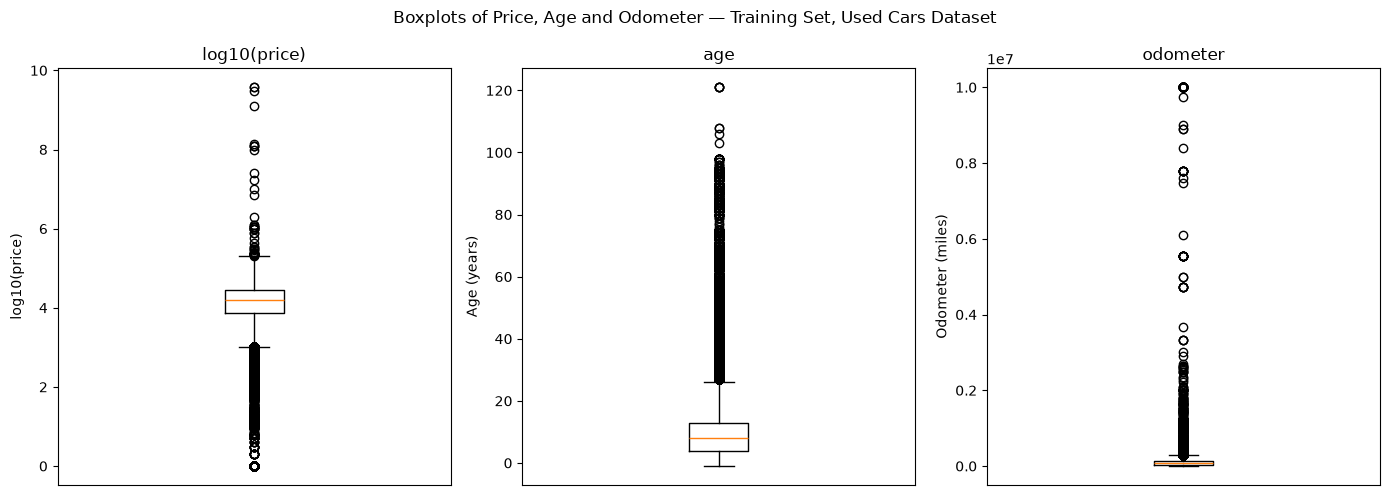

In [26]:
# Plot one boxplot per variable in the training set; price is shown on the log10 scale.
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 5))

axes[0].boxplot(log_price_train)
axes[0].set_title("log10(price)")
axes[0].set_ylabel("log10(price)")

axes[1].boxplot(train_df["age"])
axes[1].set_title("age")
axes[1].set_ylabel("Age (years)")

axes[2].boxplot(train_df["odometer"])
axes[2].set_title("odometer")
axes[2].set_ylabel("Odometer (miles)")

# Remove the tick labels under the boxes, since each panel already has a title.
for ax in axes:
    ax.set_xticks([])

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Boxplots of Price, Age and Odometer — Training Set, Used Cars Dataset")
plt.tight_layout()
plt.show()

In [27]:
# Show the most frequent prices among the training listings below the lower price limit.
low_price = train_df[train_df["price"] < lower_price]
low_price["price"].value_counts().head(10)

price
1       1286
1000     733
99       639
500      593
199      219
700      216
800      195
900      127
100      105
999      101
Name: count, dtype: int64

In [28]:
# Show the 10 highest prices among the training listings above the upper price limit.
high_price = train_df[train_df["price"] > upper_price]
high_price.sort_values("price", ascending=False).head(10)[["price", "manufacturer", "model", "age", "odometer"]]

,price,manufacturer,model,age,odometer
318592,3736928711,toyota,tundra,14.0,164000.0
356716,3736928711,toyota,4runner,22.0,211000.0
91576,3024942282,mercedes-benz,benz e320,21.0,100000.0
153082,1234567890,volvo,vnl,15.0,200000.0
230753,135008900,nissan,titan se kingcab,13.0,110500.0
137807,123456789,buick,regal,22.0,96000.0
193736,123456789,chevrolet,cruze,6.0,64181.0
288356,123456789,chevrolet,project,56.0,100000.0
1838,99999999,ford,ranger,28.0,99999.0
379133,25003000,chevrolet,camaro,30.0,200000.0


In [29]:
# Show a random sample of the training listings with an age above the upper limit.
old_vehicles = train_df[train_df["age"] > upper_age]
old_vehicles.sample(10, random_state=RANDOM_STATE)[["age", "manufacturer", "model", "price", "odometer"]]

,age,manufacturer,model,price,odometer
426545,44.0,chevrolet,c20 silverado,14000,86225.0
315122,36.0,volkswagen,vanagon,7500,140000.0
386380,27.0,chevrolet,z28 camaro,6000,164000.0
49742,27.0,chevrolet,s10 pickup,2000,207585.0
52104,29.0,ford,f-350,4500,102059.0
2524,70.0,ford,custom,18951,46016.0
301159,37.0,cadillac,seville,6999,50500.0
113694,53.0,chevrolet,camaro,43500,43320.0
135016,29.0,mitsubishi,pajero,11500,126000.0
393143,48.0,volkswagen,type iii,4500,38500.0


In [30]:
# Show a random sample of the training listings with an odometer reading above the upper limit.
high_mileage = train_df[train_df["odometer"] > upper_odometer]
high_mileage.sample(10, random_state=RANDOM_STATE)[["odometer", "manufacturer", "model", "age", "price"]]

,odometer,manufacturer,model,age,price
327586,309000.0,honda,pilot,15.0,2995
52596,340000.0,ford,f-350,16.0,12000
106327,340000.0,ram,1500,16.0,5500
345069,284000.0,chrysler,town and country,19.0,2400
96798,300000.0,mercedes-benz,300d,39.0,1200
99692,293432.0,toyota,sienna,17.0,4300
367831,309260.0,ram,3500,19.0,14900
238718,9999999.0,honda,accord,23.0,2250
346422,360000.0,ford,f550 super duty,5.0,25000
249273,999999.0,chevrolet,c10,49.0,59500


### Reasoning for each limit

**Price, lower limit.** The purpose of this limit is to remove prices that are too low to be real asking prices. In the raw data, the most repeated prices below \$1,000 are \$1 (1,637 listings) and \$99 (803 listings). 1,637 different vehicles cannot all be worth exactly \$1, so these prices are placeholders typed by sellers and not market prices. The table of the most frequent flagged prices shows which values the lower limit removes. It includes placeholders such as \$1 (1,286 listings) and \$99 (639), but also round prices such as \$1,000 (733) and \$500 (593), which can be real asking prices for cheap old cars. The lower limit therefore removes some real vehicles together with the placeholders.

**Price, upper limit.** The purpose of this limit is to remove prices that are too high to be real. In the raw data, the highest prices are keyboard sequences, values repeated across different vehicles and prices with extra zeros, so they are errors. The table of the highest flagged prices shows the listings the upper limit removes. Between the upper limit and those absurd values there are also real luxury and exotic vehicles, which are removed too, because the project focuses on mainstream used cars.

**Age.** The upper limit removes the oldest vehicles. The sample shows which kind of vehicle they are, and the classic cars found in the raw data have a price that depends on collector value and not on age and mileage. The lower limit is below zero, so no vehicle is flagged for being too new.

**Odometer.** The upper limit removes the highest mileages, which include the readings of 10,000,000 miles that would distort the scaling. The sample shows the vehicles that exceed the limit, and some of them are real vehicles with very high mileage, which are removed as well. The lower limit is below zero, so no vehicle is flagged for having too few miles.

In [31]:
# Keep only the training listings inside the limits of the three variables.
train_mask = (
    train_df["price"].between(lower_price, upper_price)
    & train_df["age"].between(lower_age, upper_age)
    & train_df["odometer"].between(lower_odometer, upper_odometer)
)
train_clean = train_df[train_mask]

# Apply the limits calculated on the training set to the test set.
test_mask = (
    test_df["price"].between(lower_price, upper_price)
    & test_df["age"].between(lower_age, upper_age)
    & test_df["odometer"].between(lower_odometer, upper_odometer)
)
test_clean = test_df[test_mask]

# Report how many rows were removed from each set.
outlier_removal = pd.DataFrame({
    "Rows before": [len(train_df), len(test_df)],
    "Rows after": [len(train_clean), len(test_clean)],
    "Rows removed": [len(train_df) - len(train_clean), len(test_df) - len(test_clean)]
}, index=["Training set", "Test set"])

outlier_removal["Removed (%)"] = (outlier_removal["Rows removed"] / outlier_removal["Rows before"] * 100).round(2)

outlier_removal

,Rows before,Rows after,Rows removed,Removed (%)
Training set,287112,267189,19923,6.94
Test set,71778,66799,4979,6.94


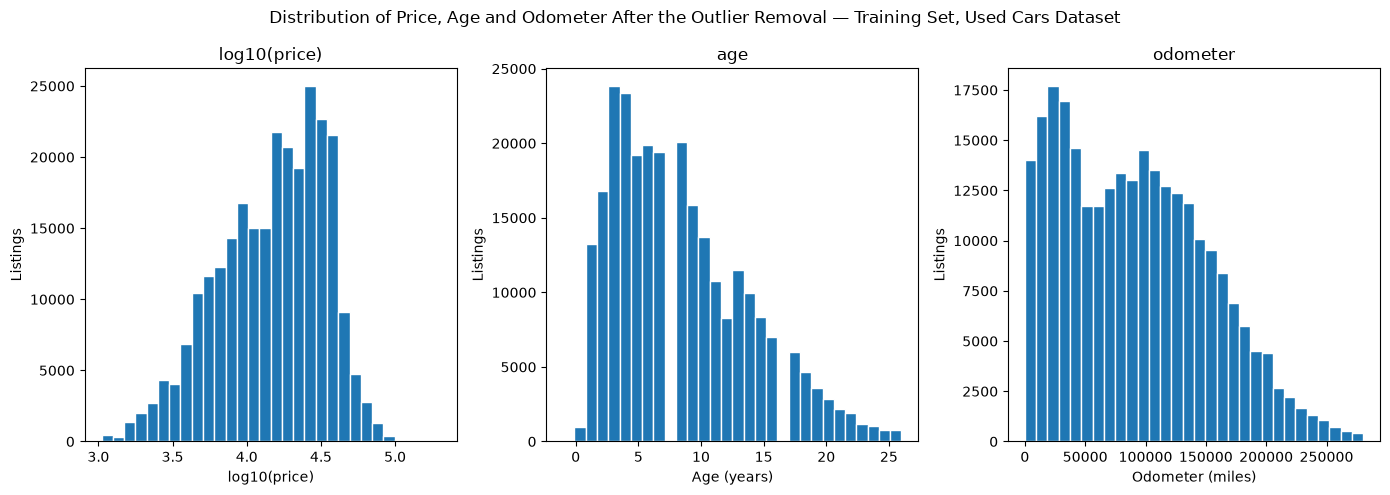

In [32]:
# Plot the distribution of each variable in the training set again after the removal.
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(14, 5))

axes[0].hist(np.log10(train_clean["price"]), bins=30, edgecolor="white")
axes[0].set_title("log10(price)")
axes[0].set_xlabel("log10(price)")

axes[1].hist(train_clean["age"], bins=30, edgecolor="white")
axes[1].set_title("age")
axes[1].set_xlabel("Age (years)")

axes[2].hist(train_clean["odometer"], bins=30, edgecolor="white")
axes[2].set_title("odometer")
axes[2].set_xlabel("Odometer (miles)")

for ax in axes:
    ax.set_ylabel("Listings")

# Add a title and adjust spacing so it does not overlap the subplot titles.
plt.suptitle("Distribution of Price, Age and Odometer After the Outlier Removal — Training Set, Used Cars Dataset")
plt.tight_layout()
plt.show()

In [33]:
# Separate the target (price) from the predictors in both sets.
X_train = train_clean.drop(columns=["price"])
y_train = train_clean["price"]

X_test = test_clean.drop(columns=["price"])
y_test = test_clean["price"]

# Report the shape of each set.
pd.DataFrame({
    "Rows": [X_train.shape[0], X_test.shape[0], y_train.shape[0], y_test.shape[0]],
    "Columns": [X_train.shape[1], X_test.shape[1], 1, 1]
}, index=["X_train", "X_test", "y_train", "y_test"])

,Rows,Columns
X_train,267189,10
X_test,66799,10
y_train,267189,1
y_test,66799,1


### Outlier findings

The limits table reports the limits calculated on the training set and the share of training listings outside them, and the removal table reports how many listings were removed from each set. The comparison of scales shows why price is analyzed on the log scale, and the tables of flagged listings show what each limit removes.

The test set was filtered with the limits of the training set, so its removal share can differ slightly from the one in the training set. After the removal, the target is separated from the predictors and the shapes of the four objects are reported.

## 12. Numeric features: skewness and scaling

Skewed variables are first transformed to look more like a normal distribution and then scaled. The order matters: scaling first would squeeze most of the data into a narrow range, and the transformation would lose much of its effect.

Histograms and Q-Q plots of `age` and `odometer` in the training set show how far they are from a normal distribution, and their skewness is measured before and after each step. The Yeo-Johnson transformation is used instead of Box-Cox because `age` contains zeros (vehicles of the reference model year) and the value -1 (next-model-year vehicles kept in section 9), and Box-Cox only accepts strictly positive values. After the transformation, the Min-Max scaler brings both variables to the range 0 to 1. Both steps are fitted on the training set only. Test values outside the range seen in training can fall slightly outside 0 to 1.

The target `price` is not transformed. It stays in dollars so that future predictions can be read directly, and a transformation of the target can be tested at the modeling stage. Its histogram and Q-Q plot are shown only for reference.

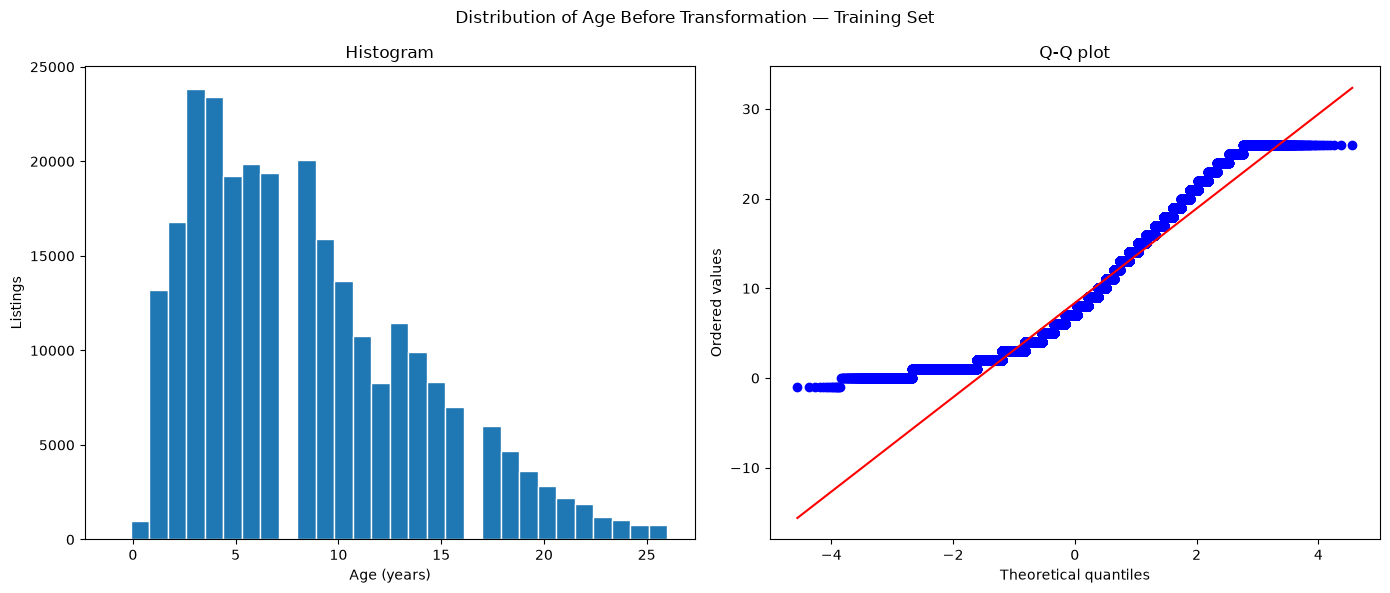

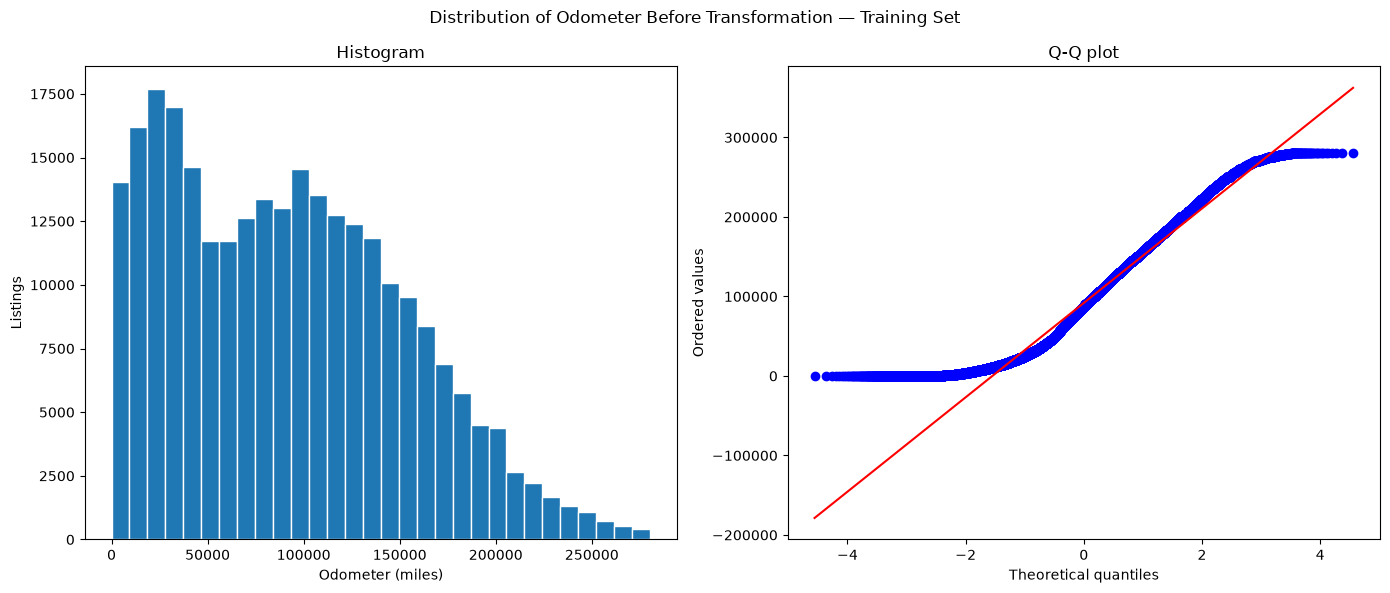

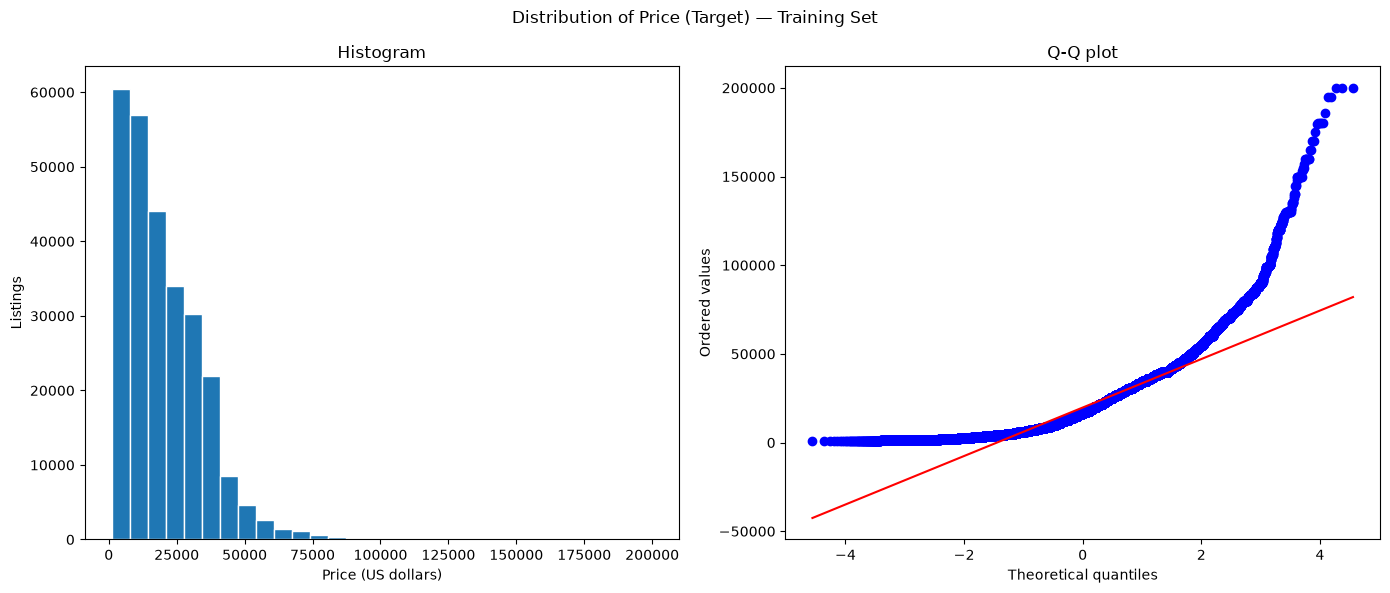

In [34]:
# Define a function that plots the histogram and the Q-Q plot of a numeric series side by side.
def diagnostic_plots(series, name, unit):
    fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 6))

    # Plot the histogram.
    axes[0].hist(series, bins=30, edgecolor="white")
    axes[0].set_title("Histogram")
    axes[0].set_xlabel(unit)
    axes[0].set_ylabel("Listings")

    # Plot the Q-Q plot against a normal distribution.
    stats.probplot(series, dist="norm", plot=axes[1])
    axes[1].set_title("Q-Q plot")
    axes[1].set_xlabel("Theoretical quantiles")
    axes[1].set_ylabel("Ordered values")

    # Add a title and adjust spacing so it does not overlap the subplot titles.
    fig.suptitle(f"Distribution of {name}")
    plt.tight_layout()
    plt.show()

# Plot the numeric variables of the training set before any transformation.
diagnostic_plots(X_train["age"], "Age Before Transformation — Training Set", "Age (years)")
diagnostic_plots(X_train["odometer"], "Odometer Before Transformation — Training Set", "Odometer (miles)")
diagnostic_plots(y_train, "Price (Target) — Training Set", "Price (US dollars)")

In [35]:
# Select the numeric predictors and work on copies, so the original training and test sets stay unchanged.
num_vars = ["age", "odometer"]

X_train_num = X_train[num_vars].copy()
X_test_num = X_test[num_vars].copy()

# Measure the skewness of the training set before any transformation.
skewness_before = X_train_num.skew()

In [36]:
# Fit Yeo-Johnson on the training set and apply it to both sets.
power_transformer = PowerTransformer(method="yeo-johnson", standardize=False)

X_train_yj = pd.DataFrame(
    power_transformer.fit_transform(X_train_num),
    columns=num_vars,
    index=X_train_num.index
)

X_test_yj = pd.DataFrame(
    power_transformer.transform(X_test_num),
    columns=num_vars,
    index=X_test_num.index
)

In [37]:
# Fit Min-Max scaling on the training set and apply it to both sets.
minmax_scaler = MinMaxScaler()

numeric_scaled_train_df = pd.DataFrame(
    minmax_scaler.fit_transform(X_train_yj),
    columns=num_vars,
    index=X_train_yj.index
)

numeric_scaled_test_df = pd.DataFrame(
    minmax_scaler.transform(X_test_yj),
    columns=num_vars,
    index=X_test_yj.index
)

In [38]:
# Summarize the skewness at each step and the lambda fitted by Yeo-Johnson in one table.
transformation_summary = pd.DataFrame(index=num_vars)

transformation_summary["Skewness before"] = skewness_before
transformation_summary["Skewness after Yeo-Johnson"] = X_train_yj.skew()
transformation_summary["Skewness after Min-Max"] = numeric_scaled_train_df.skew()

transformation_summary.round(3)

,Skewness before,Skewness after Yeo-Johnson,Skewness after Min-Max
age,0.785,-0.041,-0.041
odometer,0.458,-0.198,-0.198


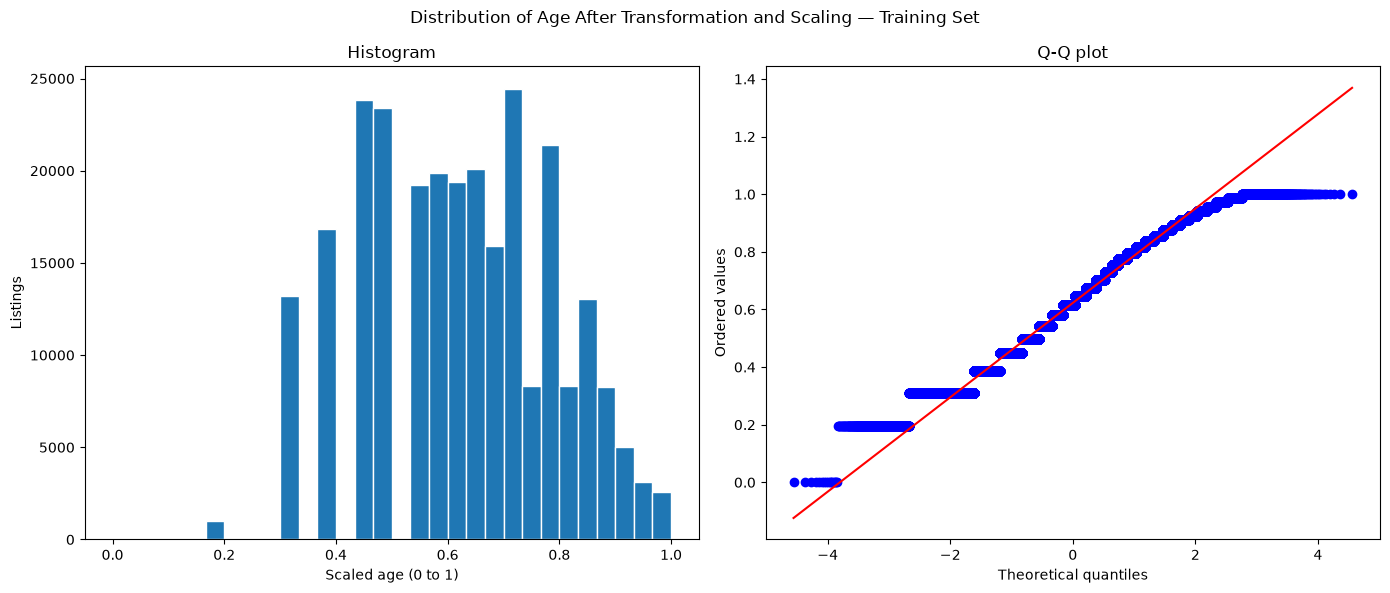

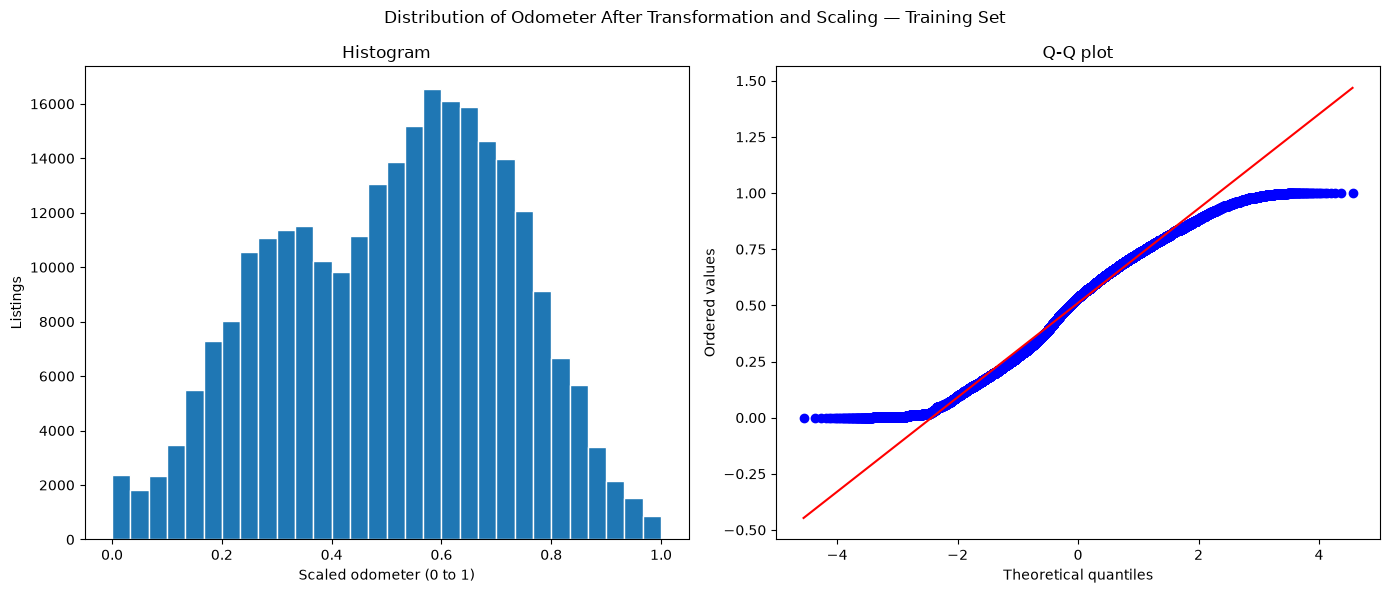

In [39]:
# Plot the histograms and the Q-Q plots again to check the effect of both steps.
diagnostic_plots(numeric_scaled_train_df["age"], "Age After Transformation and Scaling — Training Set", "Scaled age (0 to 1)")
diagnostic_plots(numeric_scaled_train_df["odometer"], "Odometer After Transformation and Scaling — Training Set", "Scaled odometer (0 to 1)")

### Numeric feature findings

The table above compares the skewness of each variable before the transformation, after Yeo-Johnson and after Min-Max scaling. Min-Max scaling is a linear transformation, so it leaves the skewness unchanged and only changes the range. The histograms before and after show how the shape changes. Because `age` takes whole-year values, its Q-Q plot shows steps, so the transformation reduces the asymmetry but cannot make the variable normal. The fitted parameters come from the training set only, and the test set was transformed with them.

## 13. Categorical features: encoding

The number of unique categories of each categorical variable is checked first, because it determines the encoding method.

Variables with few categories (`manufacturer`, `fuel`, `title_status`, `transmission`, `type` and `state`) are encoded with one-hot encoding, which creates one binary column per category and drops the first one to avoid redundant columns. Variables with many categories (`region` and `model`) would create hundreds or thousands of columns under one-hot encoding, so they are encoded with binary encoding, which represents each category with a short sequence of binary columns (roughly the base-2 logarithm of the number of categories).

Both encoders are fitted on the training set only. The notebook first counts the test rows with a category that does not appear in the training set. Those categories do not stop the pipeline: the one-hot encoder is set to ignore them (all the columns of that variable are 0, the same pattern as the dropped first category), and the binary encoder assigns them a reserved code for unknown categories. Both sets keep the same number of columns. Model names are typed by sellers and have a very large number of variants, so the `model` encoding is a practical compromise rather than a clean representation.

In [40]:
# Count the unique categories of each categorical variable in the training set.
cat_vars = X_train.describe(include="str").T
cat_vars["unique"] = cat_vars["unique"].astype(int)
cat_vars = cat_vars.sort_values(by="unique", ascending=False)

cat_vars

,count,unique,top,freq
model,267189,16407,f-150,5208
region,267189,404,columbus,2350
state,267189,51,ca,29555
manufacturer,267189,40,ford,45645
type,267189,14,sedan,56752
title_status,267189,6,clean,258266
fuel,267189,5,gas,226026
transmission,267189,3,automatic,209177


In [41]:
# Split the variables into low and high cardinality lists
highly_cardinal_variables = ['model', 'region']
few_cardinal_variables = ['state', 'manufacturer', 'type', 'title_status', 'fuel', 'transmission']

In [42]:
# Count the test rows whose category does not appear in the training set.
variables_to_check = highly_cardinal_variables + few_cardinal_variables
unseen_rows = []

for variable in variables_to_check:
    unseen = ~X_test[variable].isin(X_train[variable].unique())
    unseen_rows.append(unseen.sum())

unseen_summary = pd.DataFrame(
    {"Test rows with an unseen category": unseen_rows},
    index=variables_to_check
)
unseen_summary["Share of test rows (%)"] = (unseen_summary["Test rows with an unseen category"] / len(X_test) * 100).round(2)

unseen_summary

,Test rows with an unseen category,Share of test rows (%)
model,1881,2.82
region,0,0.00
state,0,0.00
manufacturer,0,0.00
type,0,0.00
title_status,0,0.00
fuel,0,0.00
transmission,0,0.00


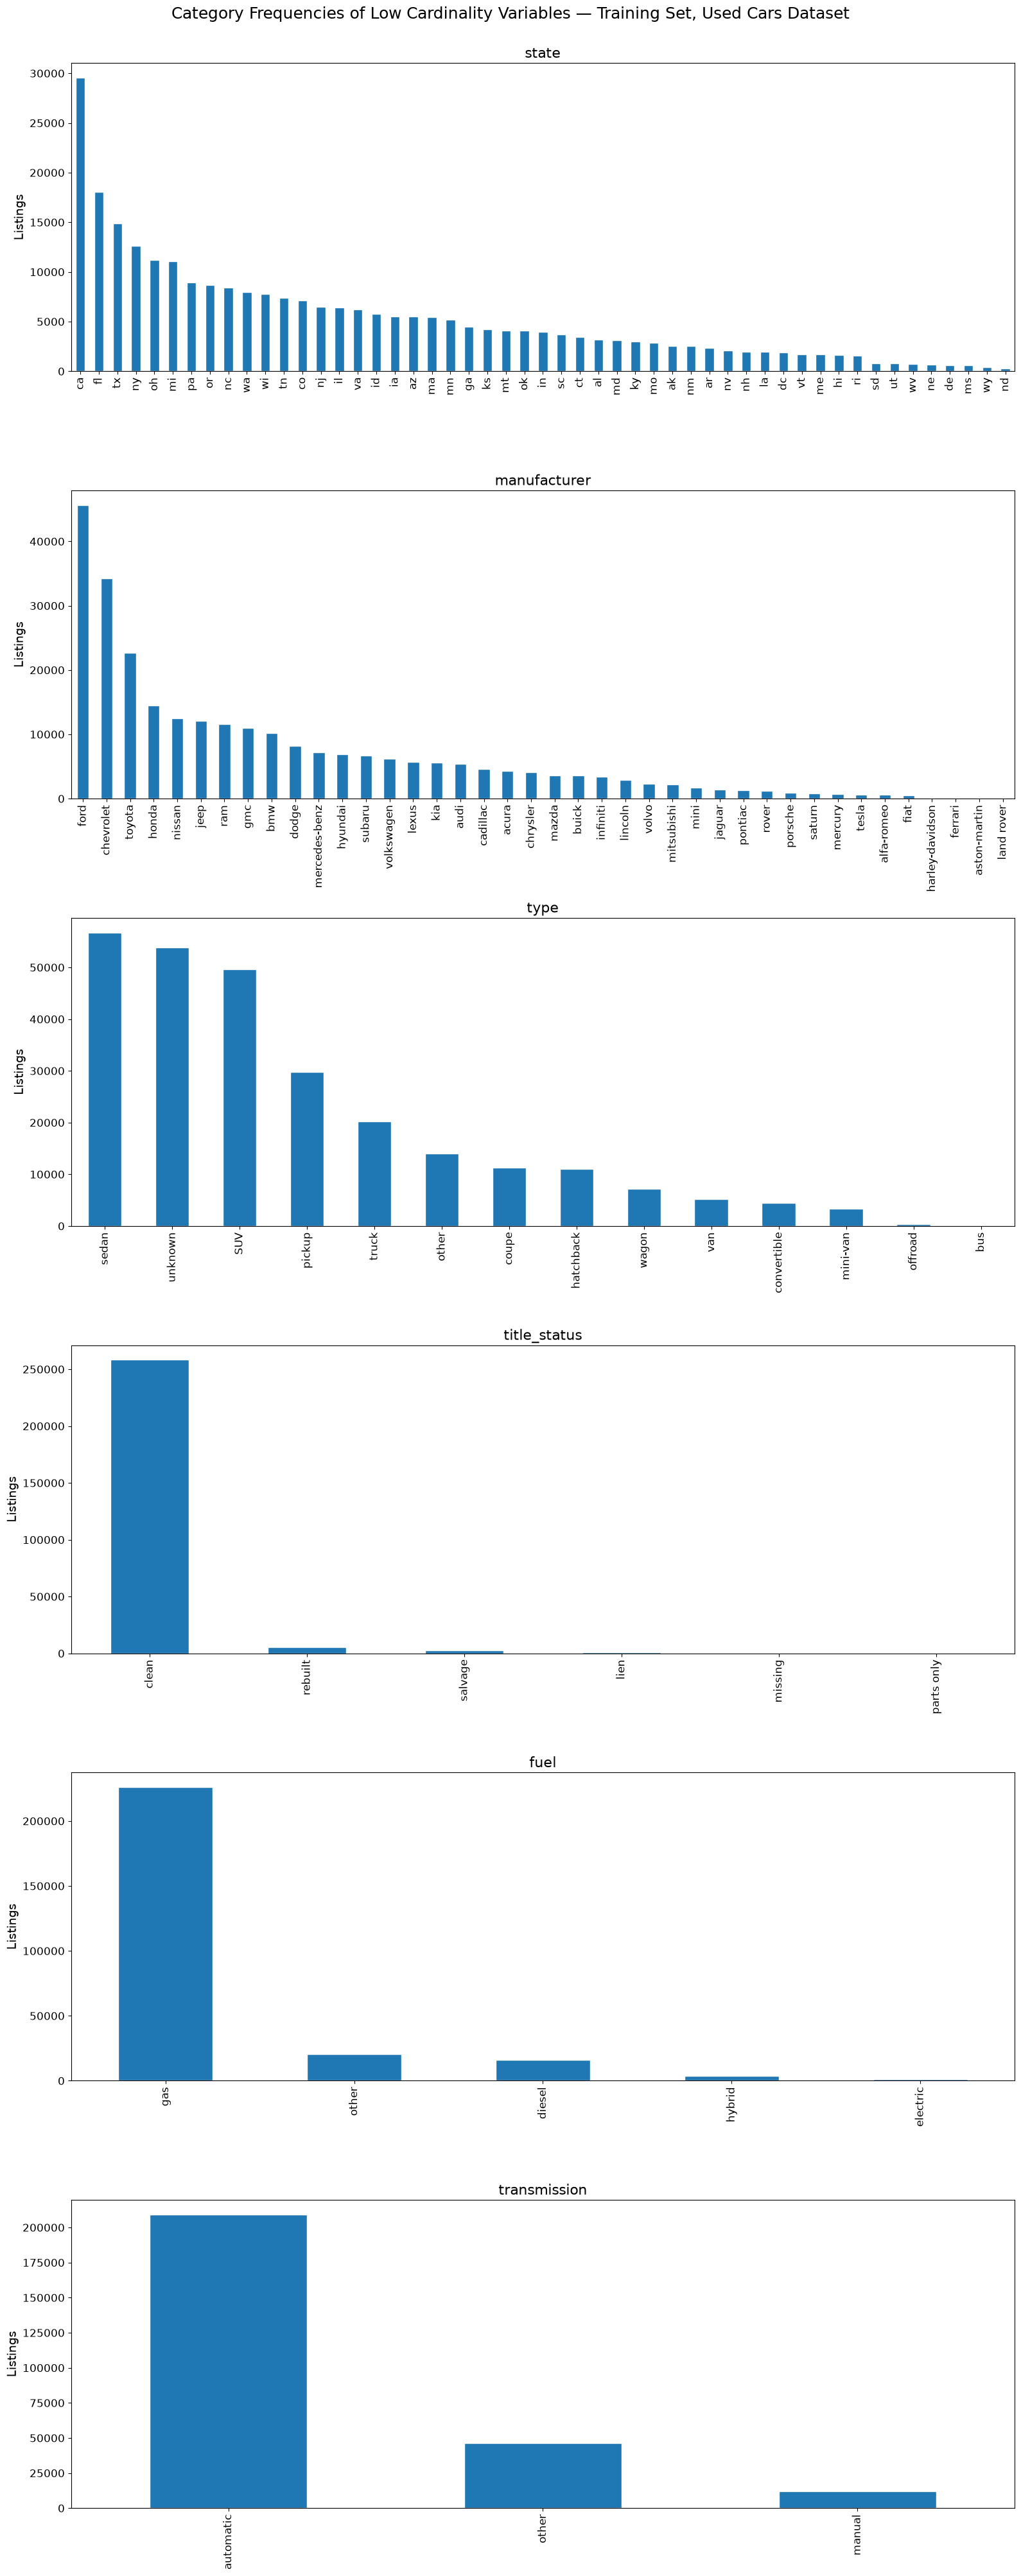

In [43]:
# Plot the category frequencies of the low cardinality variables in the training set.
fig, axes = plt.subplots(6, 1, figsize=(16, 40))

for ax, variable in zip(axes, few_cardinal_variables):
    X_train[variable].value_counts().plot(kind="bar", ax=ax, edgecolor="white")

    ax.set_title(variable, fontsize=16)
    ax.set_xlabel("")
    ax.set_ylabel("Listings", fontsize=14)
    ax.tick_params(axis="x", labelrotation=90, labelsize=12)
    ax.tick_params(axis="y", labelsize=12)

fig.suptitle("Category Frequencies of Low Cardinality Variables — Training Set, Used Cars Dataset", fontsize=18, y=1.002)

plt.tight_layout()
plt.show()

In [44]:
# Fit one-hot encoding on the training set and apply it to both sets.
onehot_encoder = OneHotEncoder(drop="first", handle_unknown="ignore")

X_train_onehot = onehot_encoder.fit_transform(X_train[few_cardinal_variables])
X_test_onehot = onehot_encoder.transform(X_test[few_cardinal_variables])

# Convert encoded data into DataFrames.
few_encoded_train_df = pd.DataFrame(
    X_train_onehot.toarray(),
    columns=onehot_encoder.get_feature_names_out(few_cardinal_variables),
    index=X_train.index
)

few_encoded_test_df = pd.DataFrame(
    X_test_onehot.toarray(),
    columns=onehot_encoder.get_feature_names_out(few_cardinal_variables),
    index=X_test.index
)

# Preview the first rows of the one-hot encoded training set.
few_encoded_train_df.head()

,state_al,state_ar,state_az,state_ca,state_co,state_ct,state_dc,state_de,state_fl,state_ga,...,title_status_missing,title_status_parts only,title_status_rebuilt,title_status_salvage,fuel_electric,fuel_gas,fuel_hybrid,fuel_other,transmission_manual,transmission_other
101379,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
200253,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
308157,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
318493,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
230413,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


In [45]:
# Fit binary encoding on the training set and apply it to both sets.
binary_encoder = BinaryEncoder(cols=highly_cardinal_variables, handle_unknown="value", handle_missing="value")

highly_encoded_train_df = binary_encoder.fit_transform(X_train[highly_cardinal_variables])
highly_encoded_test_df = binary_encoder.transform(X_test[highly_cardinal_variables])

# Preview the first rows of the binary encoded training set.
highly_encoded_train_df.head()

,model_0,model_1,model_2,model_3,model_4,model_5,model_6,model_7,model_8,model_9,...,model_14,region_0,region_1,region_2,region_3,region_4,region_5,region_6,region_7,region_8
101379,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,1
200253,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
308157,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,1,1
318493,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
230413,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,1,0,1


In [46]:
# Compare the columns created by each encoding method.
pd.DataFrame({
    "Variables": [len(few_cardinal_variables), len(highly_cardinal_variables)],
    "Columns created": [few_encoded_train_df.shape[1], highly_encoded_train_df.shape[1]]
}, index=["One-hot encoded variables", "Binary encoded variables"])

,Variables,Columns created
One-hot encoded variables,6,113
Binary encoded variables,2,24


### Encoding findings

Binary encoding of `model` and `region` creates far fewer columns than one-hot encoding would, which keeps the dataset manageable. The price of this compact representation is that the binary columns of a model name have no direct meaning on their own and that model names not seen in training share the same reserved code. The table of unseen categories shows how many test rows are affected.

## 14. Build the final dataset

The transformed numeric variables and the encoded categorical variables are combined into the final training and test sets, and the original categorical columns are removed. Indexes are reset before concatenating, because rows were removed in earlier steps and misaligned indexes would silently produce wrong joins. The index of the target is reset too, so it stays aligned row by row with the predictors.

Before closing, a set of checks confirms that the datasets are ready: no missing values, the same columns in both sets, only numeric data and one target value for each row.

In [47]:
# Reset indexes and concatenate numeric and encoded features.
numeric_scaled_train_df.reset_index(drop=True, inplace=True)
few_encoded_train_df.reset_index(drop=True, inplace=True)
highly_encoded_train_df.reset_index(drop=True, inplace=True)

X_train_final = pd.concat([
    numeric_scaled_train_df,
    few_encoded_train_df,
    highly_encoded_train_df
], axis=1)

numeric_scaled_test_df.reset_index(drop=True, inplace=True)
few_encoded_test_df.reset_index(drop=True, inplace=True)
highly_encoded_test_df.reset_index(drop=True, inplace=True)

X_test_final = pd.concat([
    numeric_scaled_test_df,
    few_encoded_test_df,
    highly_encoded_test_df
], axis=1)

# Reset the indexes of the target so it stays aligned with the predictors.
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

In [48]:
# Check the size, missing values, data types and alignment with the target of both final sets in one table.
same_columns = X_train_final.columns.equals(X_test_final.columns)

final_checks = pd.DataFrame({
    "Training set": [
        X_train_final.shape[0],
        X_train_final.shape[1],
        X_train_final.isnull().sum().sum(),
        X_train_final.select_dtypes(exclude="number").shape[1],
        len(y_train)
    ],
    "Test set": [
        X_test_final.shape[0],
        X_test_final.shape[1],
        X_test_final.isnull().sum().sum(),
        X_test_final.select_dtypes(exclude="number").shape[1],
        len(y_test)
    ]
}, index=["Rows", "Columns", "Missing values", "Non-numeric columns", "Target values"])

print("Do both sets have the same columns?", same_columns)
final_checks

Do both sets have the same columns? True


,Training set,Test set
Rows,267189,66799
Columns,139,139
Missing values,0,0
Non-numeric columns,0,0
Target values,267189,66799


### Final dataset findings

The table above reports the size of each final set and the checks. Both sets should have no missing values, no non-numeric columns, the same columns, and one target value for each row. The columns are the 2 scaled numeric variables and the one-hot and binary-encoded columns of section 13.

## 15. Conclusions and next steps

### Rows kept at each stage

In [49]:
# Count the listings left after each cleaning stage.
rows_after_outliers = len(train_clean) + len(test_clean)

listings_left = [raw_rows, rows_after_missing, rows_after_validity, rows_after_outliers]
listings_removed = [
    0,
    raw_rows - rows_after_missing,
    rows_after_missing - rows_after_validity,
    rows_after_validity - rows_after_outliers
]
previous_stage = [raw_rows, raw_rows, rows_after_missing, rows_after_validity]

# Summarize the stages in one table.
stage_table = pd.DataFrame({
    "Listings left": listings_left,
    "Listings removed": listings_removed
}, index=["Raw file", "After the missing-value rules", "After the validity rules", "After the outlier removal"])

stage_table["Removed from previous stage (%)"] = (stage_table["Listings removed"] / previous_stage * 100).round(2)

stage_table

,Listings left,Listings removed,Removed from previous stage (%)
Raw file,426880,0,0.00
After the missing-value rules,389604,37276,8.73
After the validity rules,358890,30714,7.88
After the outlier removal,333988,24902,6.94


### Key findings

- **Missing values:** six columns with 30% or more missing values were dropped, 37,276 listings (8.7%) with a missing value in a nearly complete column were removed, and the missing body type of 82,628 listings was labeled `unknown`.
- **Invalid records:** the validity rules removed listings with a price of \$0 (28,576) and default odometer readings of 2 miles or fewer (2,951). They use no hand-picked limits.
- **Outliers:** the IQR limits were calculated on the training set only (price on the log scale) and applied to both sets. They remove errors that cannot be corrected, values that distort the scaling and vehicles from other markets, such as classic cars. The limits and the share of listings removed are reported in section 11.
- **Numeric features:** `age` and `odometer` were transformed with Yeo-Johnson and scaled to the range 0 to 1, with both steps fitted on the training set only.
- **Categorical features:** six low-cardinality variables were one-hot encoded, and `model` and `region` were binary encoded.
- **Final dataset:** a training set and a test set with only numeric columns and no missing values, whose sizes are reported in section 14.

### Data-quality issues and limitations

- **Outlier removal:** the IQR rule removes some real vehicles, such as very cheap cars, luxury cars, classic cars, ordinary older vehicles and vehicles with very high mileage, so the data is best suited to the mainstream used-car market. The same limits are applied to the test set, so the evaluation of a future model describes that segment only.
- **Remaining choices:** the multiplier of 1.5, the log scale for price and the cutoff of 2 miles for default odometer readings are choices supported by the evidence in sections 9 and 11, but other reasonable choices would give a slightly different dataset.
- **Default mileage above 2 miles:** readings above 2 miles may also contain defaults (for example, 331 listings report exactly 10 miles), which are kept because the evidence does not separate them from low-mileage vehicles.
- **Cleaning rules fitted on all data:** the missing-value thresholds of section 8 were applied to the full dataset before the split.
- **Duplicated listings:** 44,773 listings (12.48% of the cleaned dataset) are exact duplicates and were not removed, so reposted ads could appear in both the training and the test set and make a future evaluation too optimistic.
- **High-cardinality encoding:** the binary encoding of `model` is a compromise, and model names not seen in training share one reserved code. 1,881 test rows (2.82%) have a model not seen in training.
- **Asking prices and one period:** the prices are asking prices from about one month in 2021, so a model trained on this data describes that market snapshot only.

### Next steps

- Train and compare regression models on the training set, and evaluate them on the test set with error metrics.
- Review the duplicated listings and decide whether to remove them or to keep each group together in one set.
- Reduce the number of `model` categories, for example by grouping rare names, and test whether it improves the encoding.
- Test a transformation of the target `price` at the modeling stage.

### Final note

This notebook prepares the data for modeling for portfolio purposes. It does not train a model, and it makes no claim about predictive performance. Its decisions are limited to the supplied dataset.